# Part 1: Data Exploration and Visualization (20 marks)

##### Q1 (5 marks) Load the dataset lifesat.csv and display the first 5 rows.

In [35]:
import pandas as pd
import matplotlib.pyplot as plt;
import seaborn as sns;
import warnings
warnings.filterwarnings("ignore")

path = r"C:\pp\ml--2026\5w\lifesat.csv"
df = pd.read_csv(path, sep = ",")

df.head(5)

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


##### Q2 (5 marks) Print basic info and summary statistics .

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               27 non-null     object 
 1   GDP per capita (USD)  27 non-null     float64
 2   Life satisfaction     27 non-null     float64
dtypes: float64(2), object(1)
memory usage: 780.0+ bytes


In [37]:
df.describe()

,GDP per capita (USD),Life satisfaction
count,27.000000,27.000000
mean,41564.521771,6.566667
std,9631.452319,0.765607
min,26456.387938,5.400000
25%,33938.289305,5.900000
50%,41627.129269,6.800000
75%,49690.580269,7.300000
max,60235.728492,7.600000


###### Q3 (10 marks) Display a scatter plot for GDP per capita vs Life Satisfaction . Add labels, title, and discuss the observed relationship

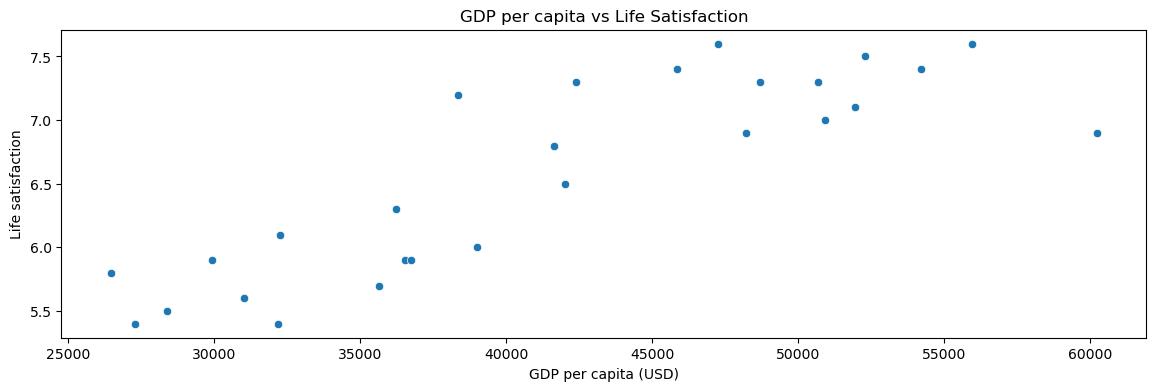

In [ ]:
plt.figure(figsize = (14,4))

plt.title("GDP per capita vs Life Satisfaction")
plt.xlabel = "GDP per capita (USD)"
plt.ylabel = "Life satisfaction"
sns.scatterplot(x = "GDP per capita (USD)" , y = "Life satisfaction", data = df)
plt.show()

In [39]:
# The scatter plot shows a clear positive relationship between GDP per capita and life satisfaction.
# As GDP per capita increases, life satisfaction also tends to increase.
# The relationship appears approximately linear, although the increase in life satisfaction becomes less steep at higher income levels.
# There are no strong outliers, and the overall pattern suggests that higher economic prosperity is associated with higher subjective well-being.

# Part 2: Linear Regression Model (30 marks)

##### Q4 (5 marks) Extract input (X) and target (y). Print their shapes.

In [40]:
X = df[["GDP per capita (USD)"]]  
y = df["Life satisfaction"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (27, 1)
y shape: (27,)


##### Q5 (10 marks) Train a Linear Regression model & Display coefficient and intercept.


In [41]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X,y)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 6.778899694341219e-05
Intercept: 3.74904942737691


##### Q6 (10 marks) Plot the predicted regression line from the model along with a scatter plot of the data.


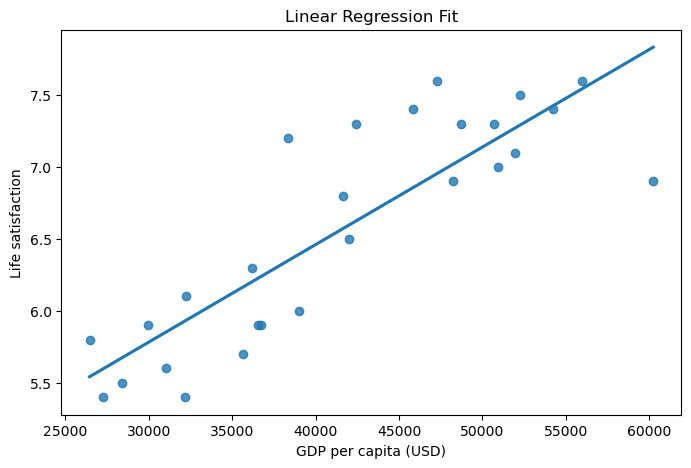

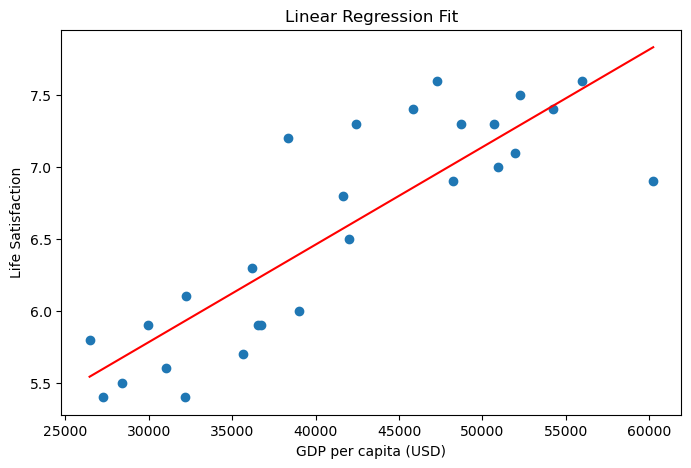

In [42]:
plt.figure(figsize=(8,5))

plt.title("Linear Regression Fit")
sns.regplot(x="GDP per capita (USD)",
    y="Life satisfaction",
    data=df,
    ci=None
           )
plt.show()

# or

plt.figure(figsize=(8,5))
plt.scatter(X, y)
y_pred = model.predict(X)

#line
plt.plot(X, y_pred, color='red')

plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life Satisfaction")
plt.title("Linear Regression Fit")

plt.show() 

##### Q7 Predict for GDP = 37655.2

In [43]:
gdp_value = [[37655.2]]
prediction = model.predict(gdp_value)

print("Predicted Life Satisfaction:", prediction[0])

Predicted Life Satisfaction: 6.3016576650804845


In [44]:
# The predicted life satisfaction for a GDP per capita of 37,655.2 USD is approximately X.
# This value is consistent with the positive relationship observed in the data,
# indicating that countries with mid-range GDP levels tend to have moderate life satisfaction scores.


# Part 3: K-Nearest Neighbors Regression (25 marks)

##### Q8 (5 marks) Train a KNeighborsRegressor (n_neighbors=3).

In [45]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X, y)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


##### Q9 Predict Life Satisfaction for GDP = 37,655.2 USD and compare with Linear Regression.

In [47]:
gdp_value = [[37655.2]]
knn_pred = knn.predict(gdp_value)

print("KNN Prediction:", knn_pred[0])


#The KNN prediction is slightly different from the Linear Regression result.
# While Linear Regression assumes a global linear relationship, KNN uses local averaging of the nearest neighbors.
# Therefore, KNN may capture local variations in the data, leading to slightly different predictions.

KNN Prediction: 6.333333333333333


##### Q10 Use n_neighbors 1, 3, 5, and 10 and print the predicted values of life satisfaction in Q10.  Plot the results using a line plot.


In [48]:
k_values = [1, 3, 5, 10]
predictions = []

for k in k_values:
    model_knn = KNeighborsRegressor(n_neighbors=k)
    model_knn.fit(X, y)
    pred = model_knn.predict([[37655.2]])
    predictions.append(pred[0])
    print(f"k={k} → Prediction: {pred[0]}")


k=1 → Prediction: 7.2
k=3 → Prediction: 6.333333333333333
k=5 → Prediction: 6.26
k=10 → Prediction: 6.369999999999999


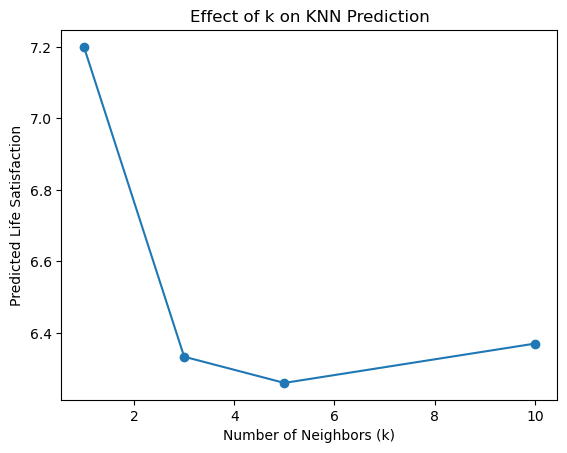

In [49]:
plt.plot(k_values, predictions, marker='o')
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Predicted Life Satisfaction")
plt.title("Effect of k on KNN Prediction")
plt.show()


In [50]:
# As k increases, the prediction becomes smoother and less sensitive to individual data points.
# Small k values may lead to overfitting, while larger k values produce more stable predictions.